In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numba import njit, prange
from tqdm import tqdm
from scipy.signal import correlate
from scipy.stats import multivariate_normal
import os
import sys
from statistics import mean

import matplotlib

from scipy.ndimage import gaussian_filter

module_path = os.path.abspath(os.path.join('..'))
if module_path not in sys.path:
    sys.path.append(module_path)

from GLOBAL.ground_truths import *
from GLOBAL.torque import *
from GLOBAL.filters import *

#max_angle = 1000000 * np.pi / 180

with np.load("../GLOBAL/data.npz") as data:
    x_data=data['x_data']
    y_data=data['y_data']

#n_trajectories = 2
#x_data = x_data[:n_trajectories, :]
#y_data = y_data[:n_trajectories, :]

def resample_spline(mean, cov):
    mean_resampled = np.repeat(mean, 2)
    diag_cov = np.diag(cov)
    diag_cov = np.repeat(diag_cov, 2)
    cov_resampled = np.diag(diag_cov)
    return mean_resampled, cov_resampled

# Find proposal

In [3]:
def plot_torques(MEANS, COVS, n_knots=None, n_samples=10000, n_phis = 200, n_examples=0, torque_scale=50, plot_edges=True, use_Bsplines=False):

    TORQUE_FN = TORQUE_BSPLINE if use_Bsplines else TORQUE
    #plt.figure(figsize=(4, 4))

    #MEANS = [m[1:] for m in MEANS]
    #COVS = [c[1:,1:] for c in COVS]
    
    phi = np.linspace(-np.pi * 0.1, 2.1 * np.pi, n_phis)
    phi_draw = phi * 180 / np.pi

    use = -1
    sample_mean = np.mean(MEANS[use:], axis=0)
    sample_cov = np.mean(np.array(COVS[use:]), axis=0)

    TORQUES = []

    SAMPLES = np.random.multivariate_normal(sample_mean, sample_cov, n_samples)


    for s in SAMPLES:
        TORQUES.append(TORQUE_FN(phi, s))

    TORQUES = np.array(TORQUES)

    Tmax = torque_scale
    Tmin = -torque_scale

    bins = np.linspace(Tmin, Tmax, n_phis)

    extent = [phi_draw.min(), phi_draw.max(), Tmin, Tmax]
    def hist1d(x):
        hist = np.histogram(x, bins=bins, density=True)[0]
        return hist / hist.max()

    density = np.apply_along_axis(hist1d, axis=0, arr=TORQUES, )

    density_ = gaussian_filter(density, (0.0,0))
    #plt.figure(dpi=300)
    cmap = matplotlib.colors.LinearSegmentedColormap.from_list("", ["white","yellowgreen"])
    plt.imshow(density_, extent=extent, aspect='auto', origin='lower', cmap=cmap)

    torque_mean = np.mean(TORQUES, axis=0)
    torque_mode = bins[np.argmax(density_, axis=0)]
    torque_std = np.std(TORQUES, axis=0)

    torque_true = TORQUE(phi, ALPHAS)

    #if n_knots is not None:
    #    phi_knots = np.linspace(0, np.pi, n_knots+2)[1:-1]
    #    torque_knots = TORQUE(phi_knots, ALPHAS)
    #
    #    plt.scatter(phi_knots, torque_knots, c='r', s=10)
    #    #for phi_ in phi_knots:
    #    #    plt.axvline(phi_, color='k', alpha=0.5, lw=0.5, ls='--')

    
    for i in range(n_examples):

        SAMPLES = np.random.multivariate_normal(sample_mean, sample_cov, 1)

        TORQUES = []
        for s in SAMPLES:
            TORQUES.append(TORQUE_FN(phi, s))
        
        plt.plot(phi_draw, TORQUES[0], lw=1, alpha=1, ls='--', c='darkgreen')

    col='olivedrab'
    qtil = 2.575829
    
    plt.plot(phi_draw, torque_mean - qtil*torque_std, '-', lw=0.7, c=col)
    plt.plot(phi_draw, torque_mean + qtil*torque_std, '-', lw=0.7, c=col)
    #plt.plot(phi, torque_mode, '--', lw=0.7, alpha=1, c=col)
    #plt.plot(phi, torque_true, '-', lw=2, alpha=1, c='r')
    if plot_edges:
        plt.axvline(0, color='k', lw=2)
        plt.axvline(360, color='k', lw=2)
    plt.grid()
    plt.ylim(Tmin, Tmax)
    plt.xticks(np.arange(0, 360+1, 90))

    

In [4]:
def plot_cov_ellipse(mean, cov, color='b'):
    phi = np.linspace(0, 2*np.pi, 100)
    chol = np.linalg.cholesky(cov[:2, :2])
    ellipse = np.array([np.cos(phi), np.sin(phi)])
    plt.plot(*(chol@ellipse + mean[:2][:, None]), c=color)
    ellipse = 2*np.array([np.cos(phi), np.sin(phi)])
    plt.plot(*(chol@ellipse + mean[:2][:, None]), c=color, ls='--')

In [5]:
d0 = 0
d1 = 1

ndims = 2
centers = np.zeros(ndims)
count = 0

In [6]:
rng = np.random.default_rng()
def learn(x_data, y_data,
          progression=range(20),
          sample_count=1024 // 64,
          torque_scale=200,
          new_samples_only=True,
          max_angle = 90 * np.pi / 180,
          particle_count=100,
          use_Bsplines = False,
          clip_parameters=1000,
          mixing_ratio=0.8,
          search_size=1,
          smoothing_factor=1.0):
    global mean, cov, ALL_COORDS, ALL_TARGET_DENSITIES, ALL_LIKELIHOODS, count
    for prog in tqdm(progression):

        ''' GENERATE NEW TEST SAMPLES '''

        test_distribution = multivariate_normal(mean=mean, cov=search_size*cov, allow_singular=False)
        coords = test_distribution.rvs(sample_count)
        likelihood = test_distribution.pdf(coords)

        props = 1 / likelihood
        props = props / np.sum(props)
        #coords = rng.choice(coords, size=sample_count, p=props)

        ''' EVALUATE POSTERIOR AT TEST POINTS '''

        logl, _, _ = calc_logl_core(x_data, y_data, dt,
                                    PE, DT, DR, FORCE_STRENGTH,
                                    coords, torque_limit=max_angle,
                                    n_particles=particle_count,
                                    clip_params=clip_parameters,
                                    use_Bsplines=use_Bsplines,
                                    )
        logl = logl - np.max(logl)
        target_density = np.exp(logl)
        target_density = target_density / np.sum(target_density)

        # (Remnant of old testing code. More stable but incorrect.)
        #ALL_COORDS = np.concatenate((ALL_COORDS, coords))
        #ALL_TARGET_DENSITIES = np.concatenate((ALL_TARGET_DENSITIES, target_density))
        #ALL_LIKELIHOODS = np.concatenate((ALL_LIKELIHOODS, likelihood))
        #ALL_LIKELIHOODS = distribution.pdf(ALL_COORDS)
        # (Delete old data, otherwise the fit isn't correct -> Mitigating above issue.)

        ALL_COORDS = coords
        ALL_TARGET_DENSITIES = target_density
        ALL_LIKELIHOODS = likelihood

        ''' CALULATE NEW MEAN AND COVARIANCE'''
        mean_old = mean
        cov_old = cov
        mean = np.average(ALL_COORDS, axis=0, weights=ALL_TARGET_DENSITIES)
        cov = np.cov(ALL_COORDS.T, aweights=ALL_TARGET_DENSITIES)

        #cov /= smoothing_factor**2

        if np.any(np.isnan(cov)):
            cov = cov_old

        # (Stabilize the fit by mixing the old and new parameters)
        #mixing_ratio = mixing_ratio
        #mean = mixing_ratio * mean + (1 - mixing_ratio) * mean_old
        #cov = mixing_ratio * cov + (1 - mixing_ratio) * cov_old

        ''' STORE PROGRESS '''

        COVS.append(cov.copy())
        MEANS.append(mean.copy())

        plt.figure(dpi=120, figsize=(5, 5))

        ''' PLOT ORIGINAL LOG PARAMETERS '''

        plt.subplot(2, 2, 1)
        plt.gca().set_facecolor('silver')
        plt.gca().title.set_text("Log likelihood")
        #chan = np.exp(ALL_TARGET_DENSITIES/10)
        chan = target_density
        plt.hexbin((ALL_COORDS)[:, d0], (ALL_COORDS)[:, d1], C=chan, gridsize=32, reduce_C_function=np.max)
        plt.axvline(centers[0], color='r', linestyle='--', lw=1)
        plt.axhline(centers[1], color='r', linestyle='--', lw=1)
        plot_cov_ellipse(mean, cov, color='w')

        ''' PLOT ROTATED PARAMETERS '''

        eivals, eivecs = np.linalg.eig(cov)
        idx = np.argsort(np.abs(eivals))[::-1]
        eivals = eivals[idx]
        eivecs = eivecs[:, idx]
        def rotate(vec):
            return np.dot(vec, eivecs)
        
        def rotate_mat(mat):
            return np.dot(np.dot(eivecs.T, mat), eivecs)
        
        plt.subplot(2, 2, 2)
        plt.gca().set_facecolor('silver')
        #chan = np.exp(ALL_TARGET_DENSITIES/10)
        chan = target_density
        plt.hexbin(rotate(ALL_COORDS)[:, d0], rotate(ALL_COORDS)[:, d1], C=chan, gridsize=32)
        plot_cov_ellipse(rotate(mean), rotate_mat(cov), color='w')


        ''' PLOT CONVERGENCE '''

        plt.subplot(2, 2, 3)

        COVS_flat = [cov_.copy() for cov_ in COVS]
        for cov_ in COVS_flat:
            np.fill_diagonal(cov_, np.nan)
        COVS_flat = [cov_.flatten() for cov_ in COVS]

        COVS_flat = np.stack(COVS_flat, axis=0)
        plt.semilogy(np.abs(COVS_flat), 'red', label='Covariances')

        COVS_flat = [np.diagonal(cov) for cov in COVS]
        COVS_flat = np.stack(COVS_flat, axis=0)
        plt.semilogy(np.abs(COVS_flat), 'blue', label='Diagonals')
        plt.xlabel("Iteration")
        plt.ylabel("Covariance matrix element")

        ''' PLOT POSTERIOR TORQUE '''

        plt.subplot(2, 2, 4)
        plot_torques(MEANS, COVS, n_knots=ndims-1, torque_scale=torque_scale, use_Bsplines=use_Bsplines)
        plt.tight_layout()
        plt.savefig(f"img/proposal_convergence{count}.png", dpi=300)
        plt.xlim(0, 180)
        plt.xlabel(r"$\varphi-\theta$")
        plt.ylabel(r"$\tau\sigma$")
        plt.show()
        count += 1

# Learning

# B-Spline Run

  0%|                                       | 0/40 [00:00<?, ?it/s]

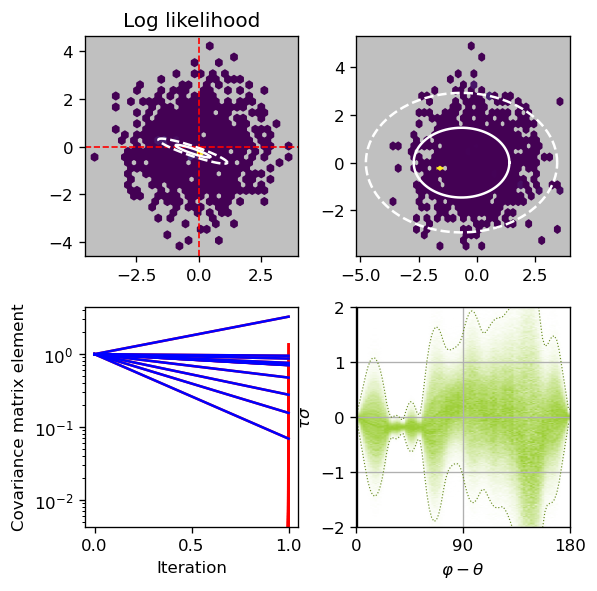

  2%|▋                           | 1/40 [10:02<6:31:42, 602.62s/it]

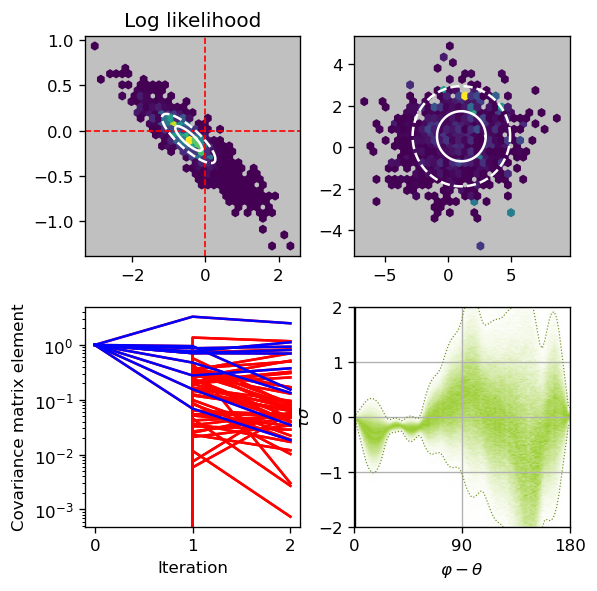

  5%|█▍                          | 2/40 [20:07<6:22:38, 604.17s/it]

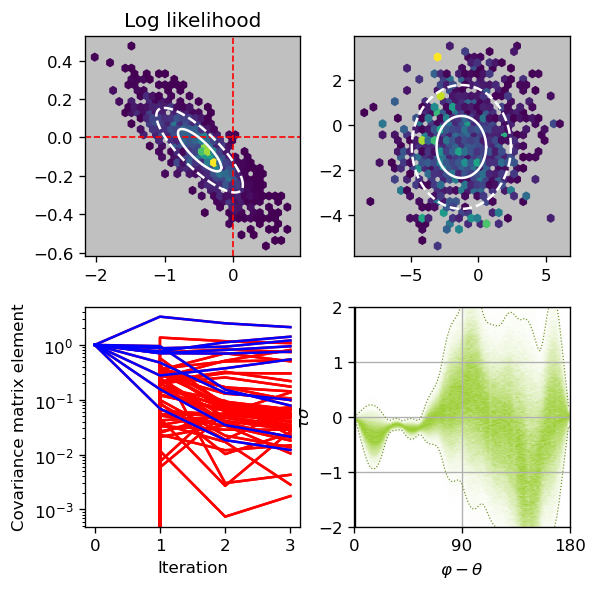

  8%|██                          | 3/40 [30:14<6:13:13, 605.23s/it]

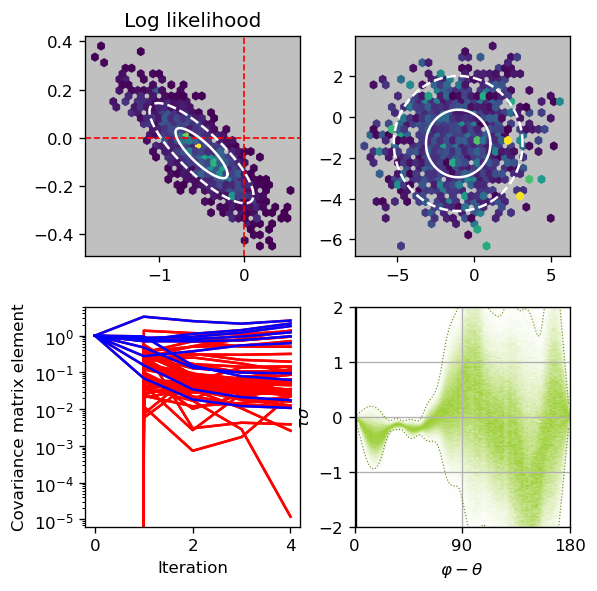

 10%|██▊                         | 4/40 [40:21<6:03:41, 606.15s/it]

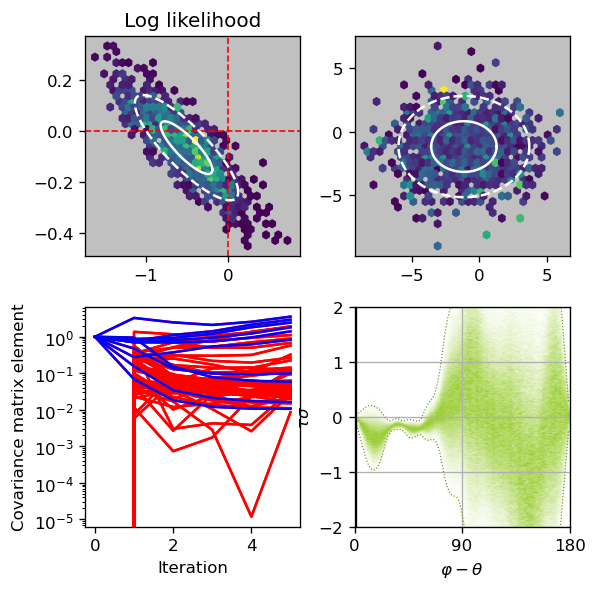

 12%|███▌                        | 5/40 [50:31<5:54:12, 607.20s/it]

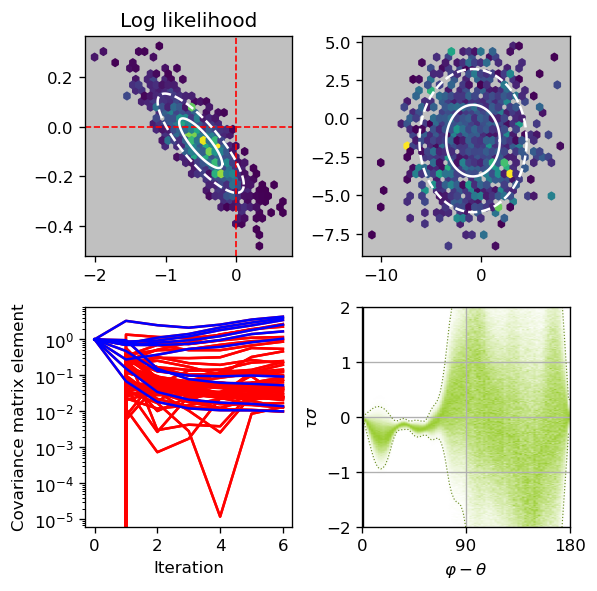

 15%|███▉                      | 6/40 [1:00:34<5:43:21, 605.94s/it]

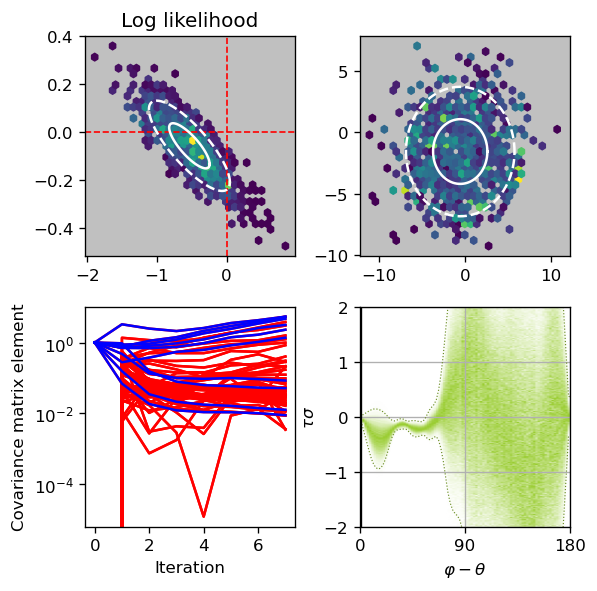

 18%|████▌                     | 7/40 [1:10:37<5:32:45, 605.02s/it]

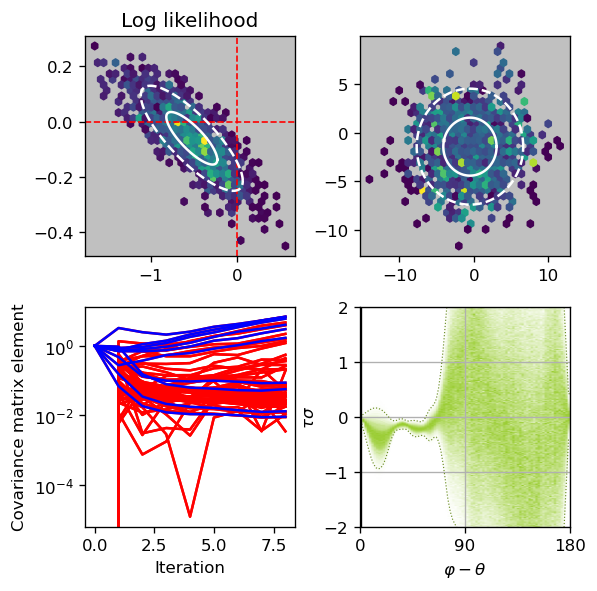

 20%|█████▏                    | 8/40 [1:20:30<5:20:39, 601.23s/it]

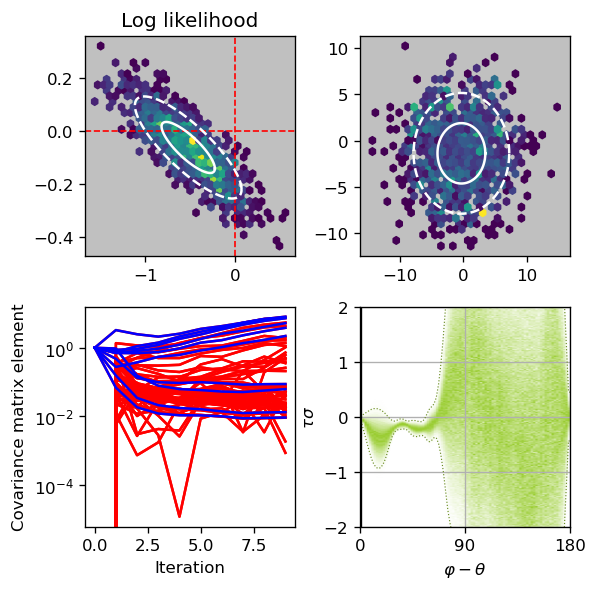

 22%|█████▊                    | 9/40 [1:29:51<5:04:06, 588.61s/it]

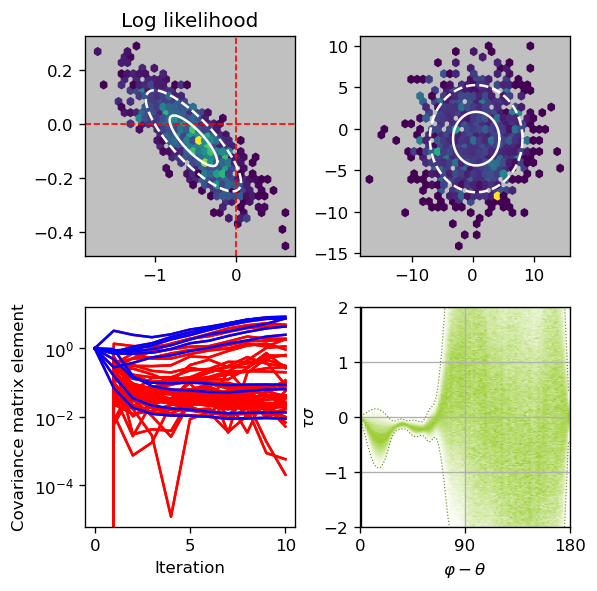

 25%|██████▎                  | 10/40 [1:39:09<4:49:32, 579.08s/it]

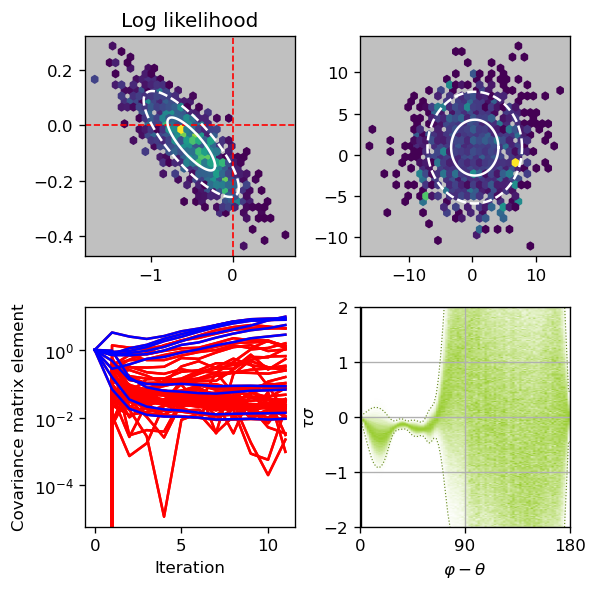

 28%|██████▉                  | 11/40 [1:48:08<4:34:00, 566.92s/it]

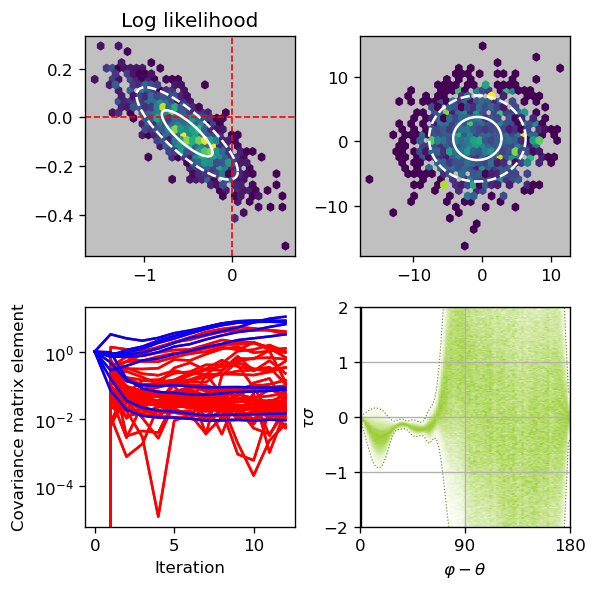

 30%|███████▌                 | 12/40 [1:56:32<4:15:36, 547.75s/it]

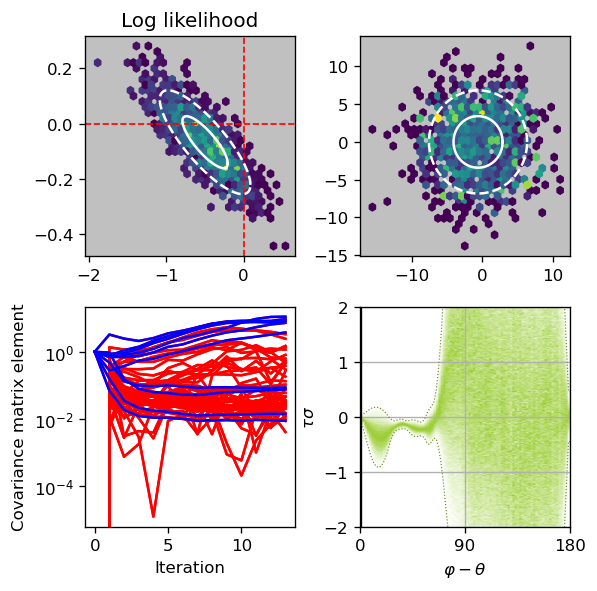

 32%|████████▏                | 13/40 [2:04:54<4:00:12, 533.80s/it]

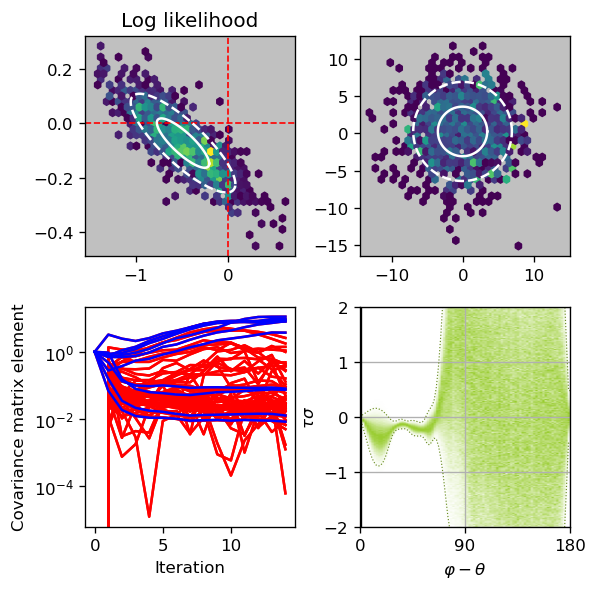

 35%|████████▊                | 14/40 [2:12:49<3:43:35, 515.98s/it]

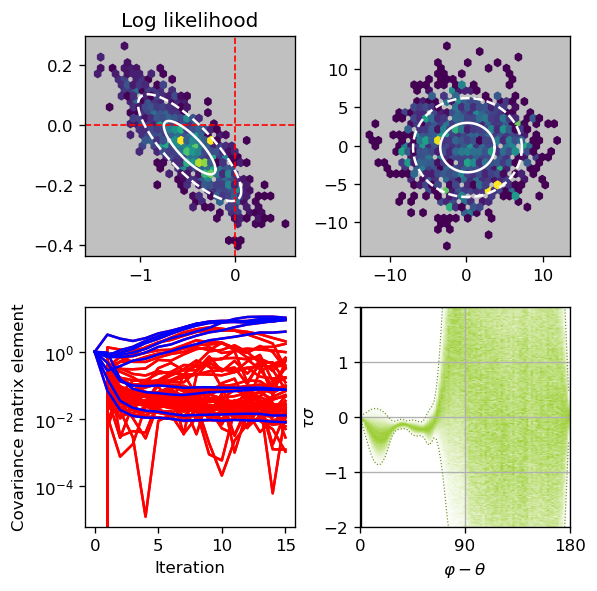

 38%|█████████▍               | 15/40 [2:20:22<3:27:11, 497.25s/it]

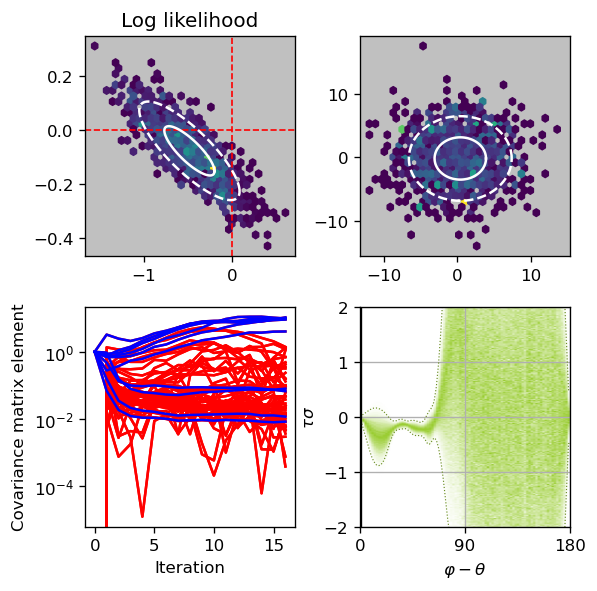

 40%|██████████               | 16/40 [2:27:36<3:11:11, 477.97s/it]

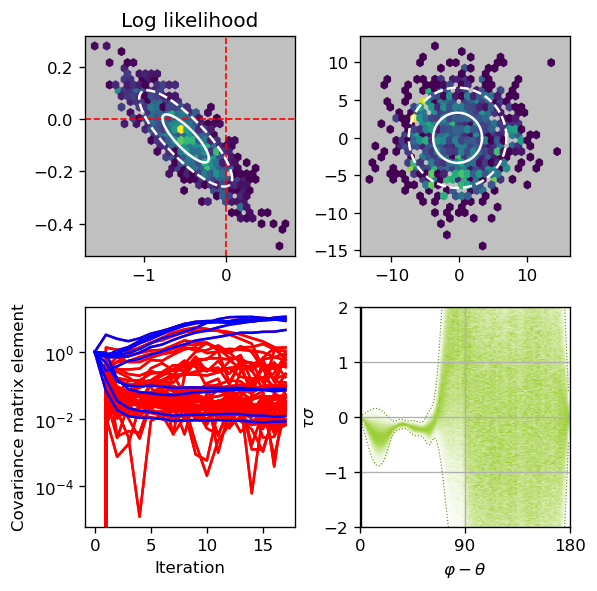

 42%|██████████▋              | 17/40 [2:34:43<2:57:22, 462.70s/it]

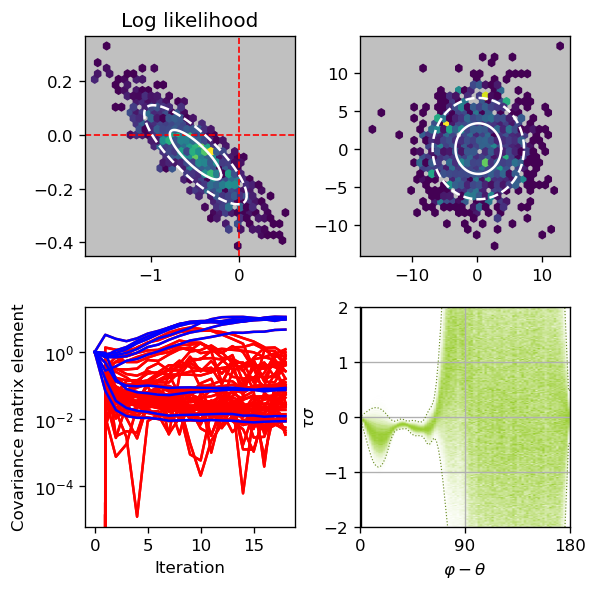

 45%|███████████▎             | 18/40 [2:41:40<2:44:36, 448.92s/it]

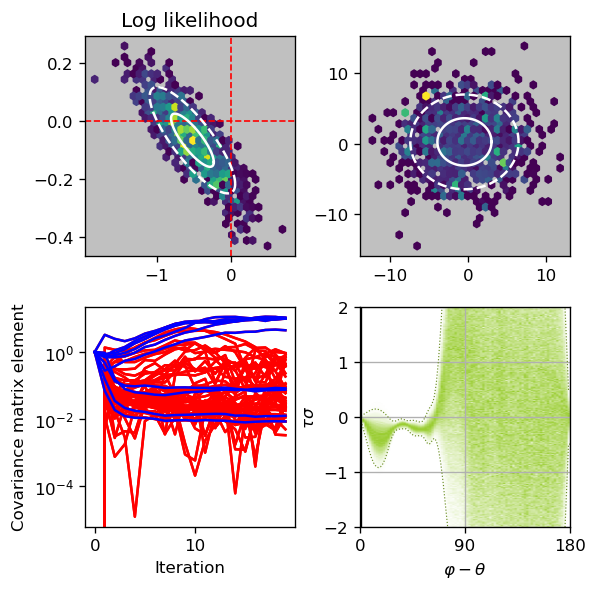

 48%|███████████▉             | 19/40 [2:48:58<2:35:58, 445.63s/it]

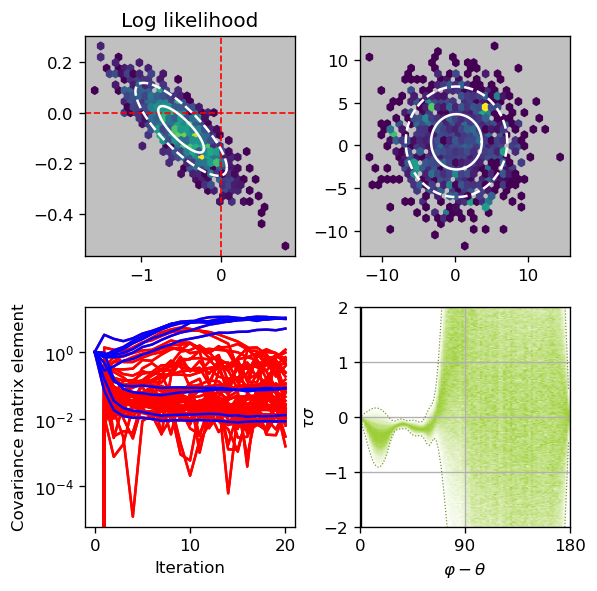

 50%|████████████▌            | 20/40 [2:56:15<2:27:42, 443.13s/it]

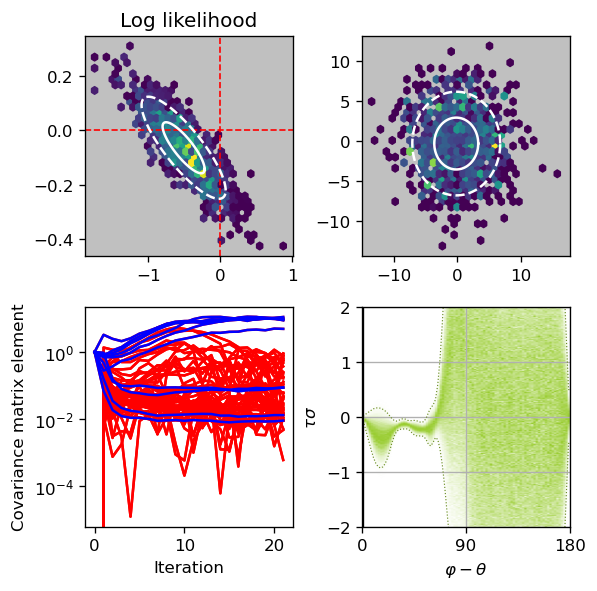

 52%|█████████████▏           | 21/40 [3:03:18<2:18:22, 436.98s/it]

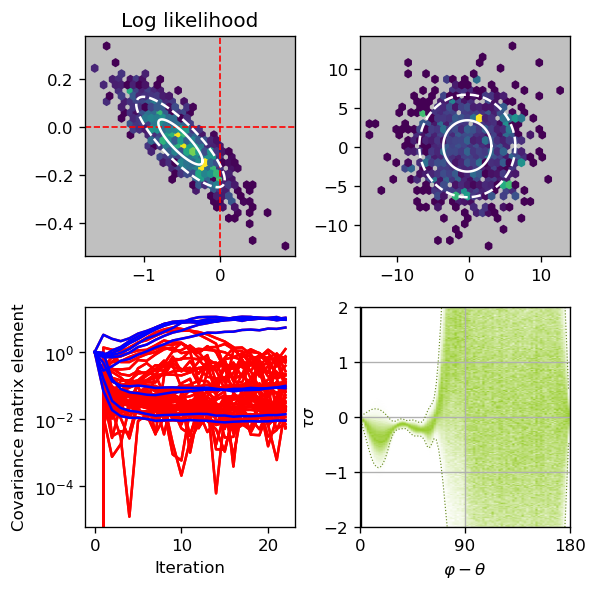

 55%|█████████████▊           | 22/40 [3:10:31<2:10:47, 435.96s/it]

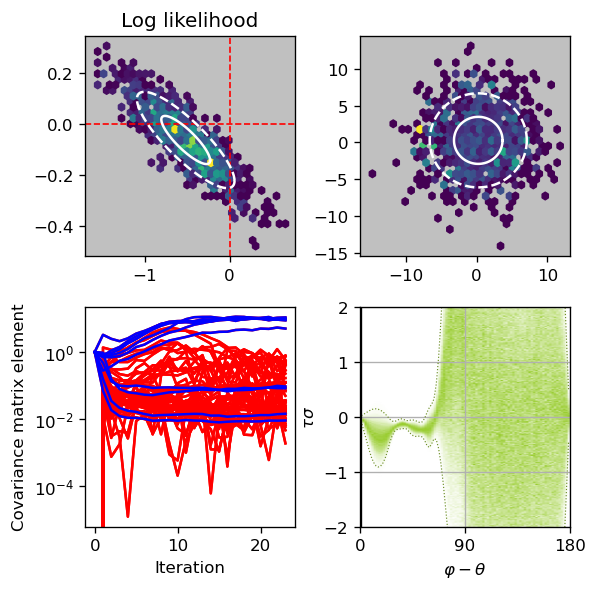

 57%|██████████████▎          | 23/40 [3:17:52<2:03:54, 437.30s/it]

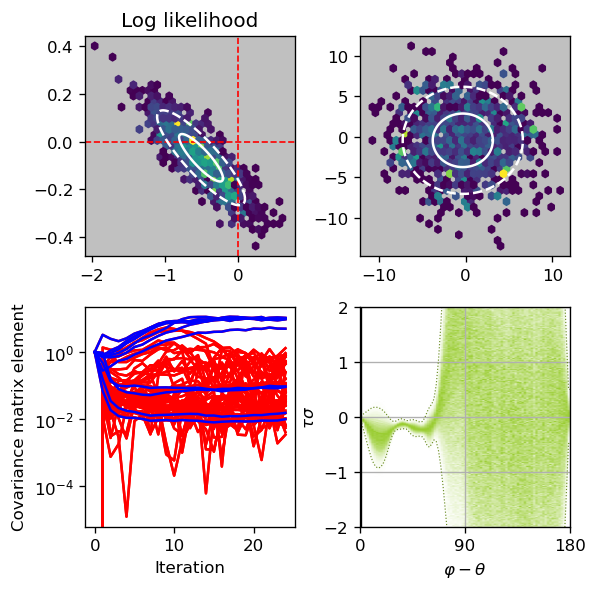

 60%|███████████████          | 24/40 [3:24:49<1:55:01, 431.36s/it]

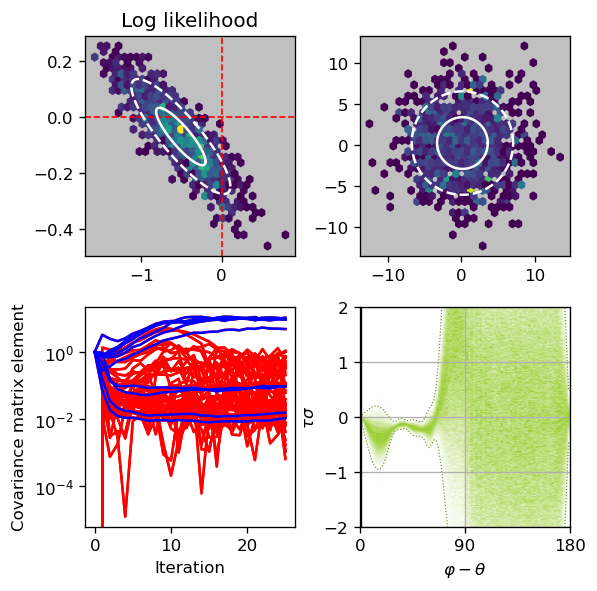

 62%|███████████████▋         | 25/40 [3:33:26<1:54:13, 456.90s/it]

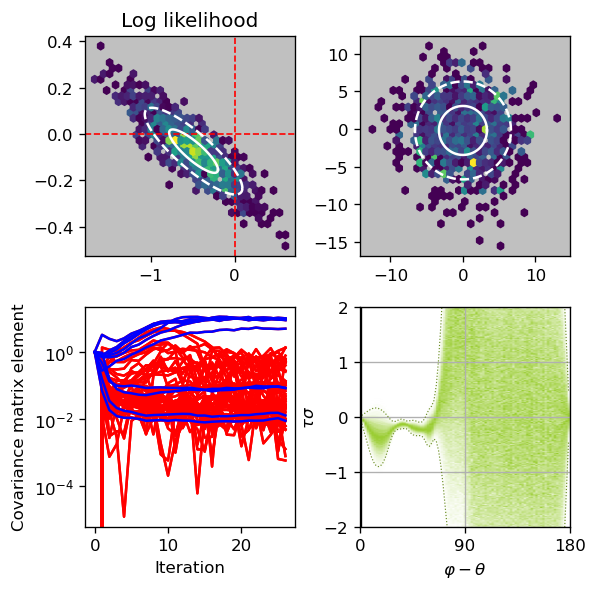

 65%|████████████████▎        | 26/40 [3:40:55<1:46:06, 454.74s/it]

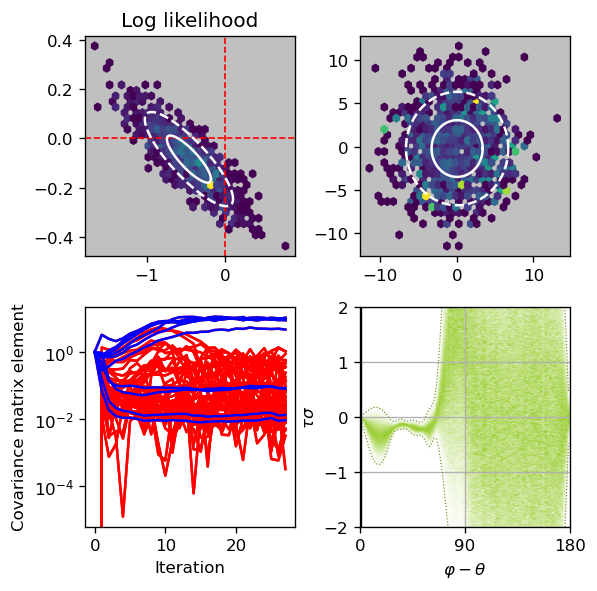

 68%|████████████████▉        | 27/40 [3:48:33<1:38:41, 455.50s/it]

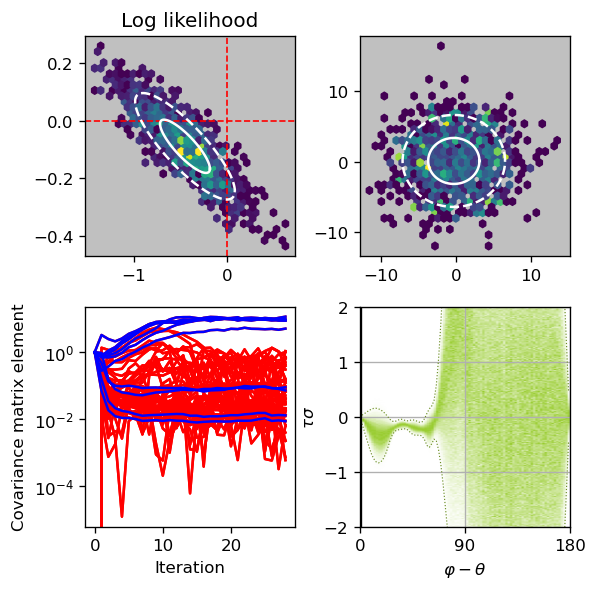

 70%|█████████████████▌       | 28/40 [3:56:05<1:30:56, 454.73s/it]

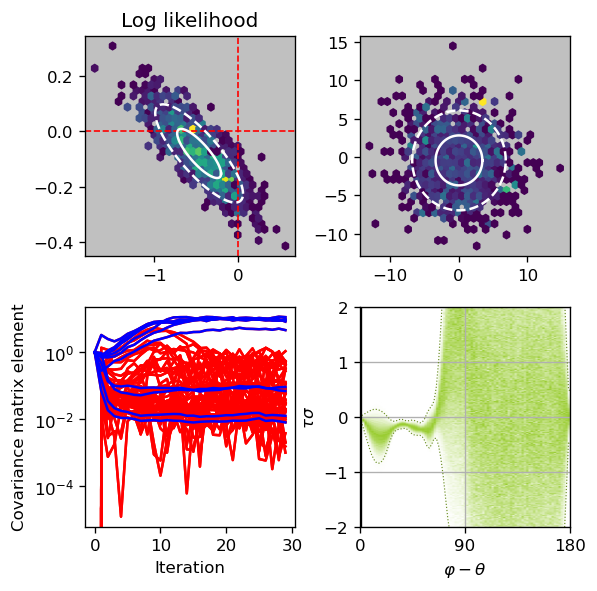

 72%|██████████████████▏      | 29/40 [4:03:28<1:22:41, 451.05s/it]

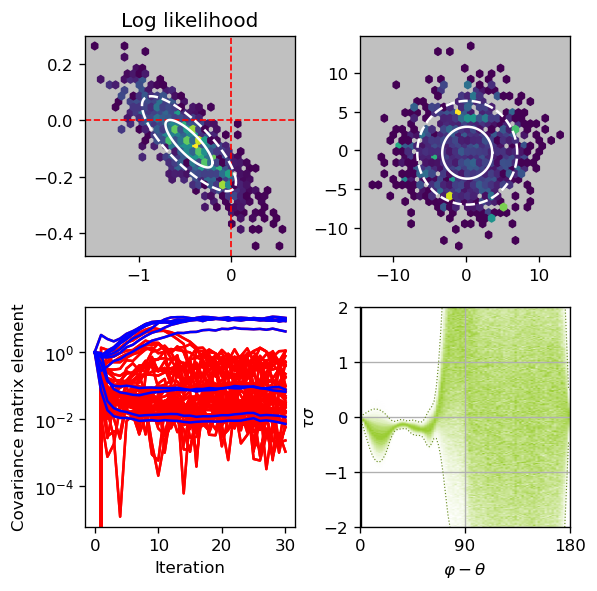

 75%|██████████████████▊      | 30/40 [4:10:43<1:14:22, 446.21s/it]

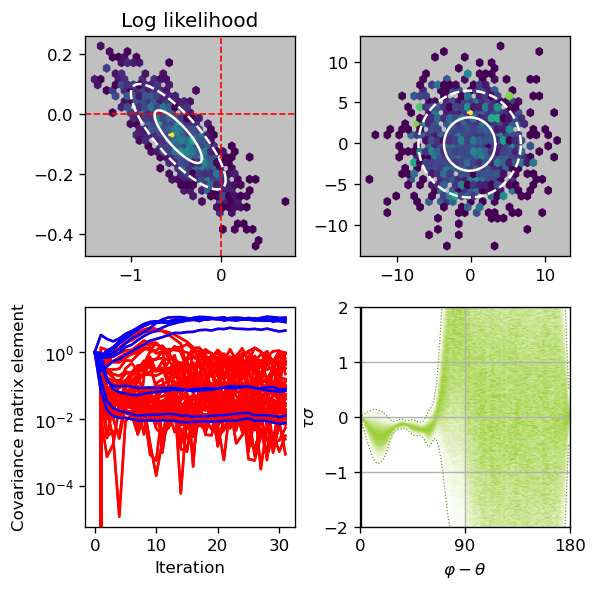

 78%|███████████████████▍     | 31/40 [4:17:50<1:06:03, 440.41s/it]

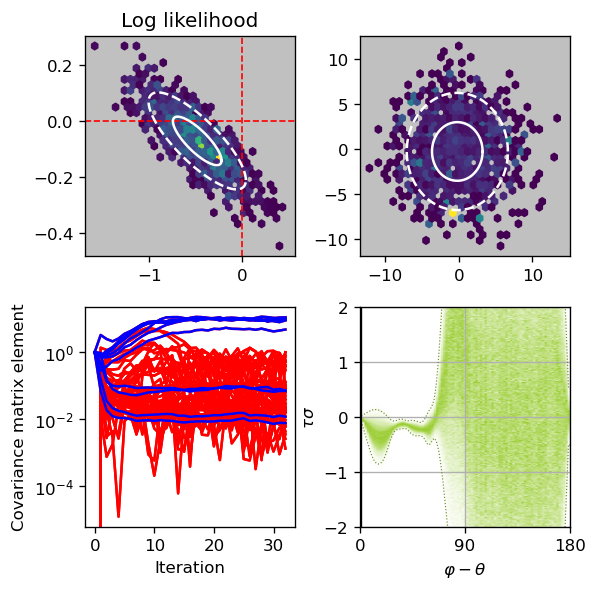

 80%|█████████████████████▌     | 32/40 [4:25:22<59:11, 443.92s/it]

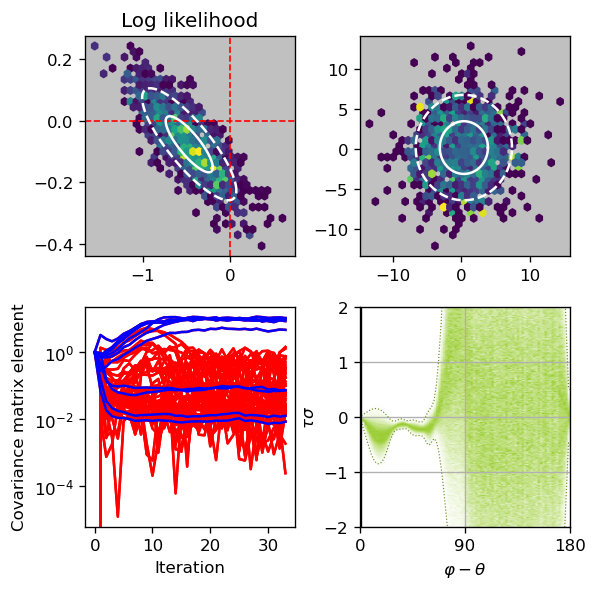

 82%|██████████████████████▎    | 33/40 [4:32:47<51:49, 444.20s/it]

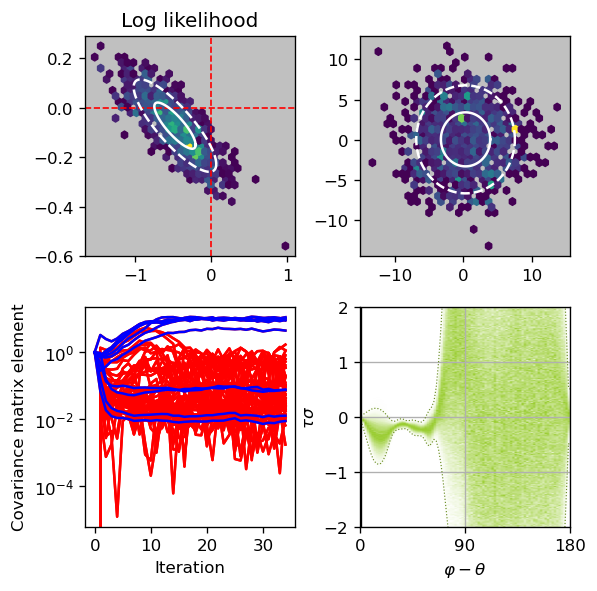

 85%|██████████████████████▉    | 34/40 [4:39:57<44:01, 440.18s/it]

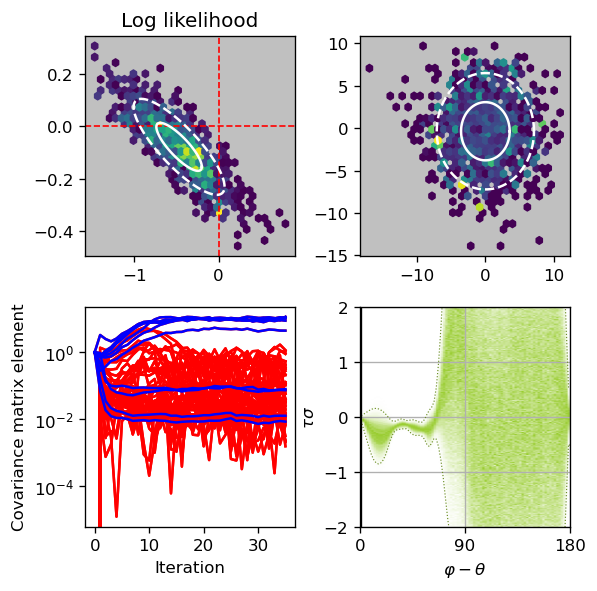

 88%|███████████████████████▋   | 35/40 [4:47:13<36:33, 438.74s/it]

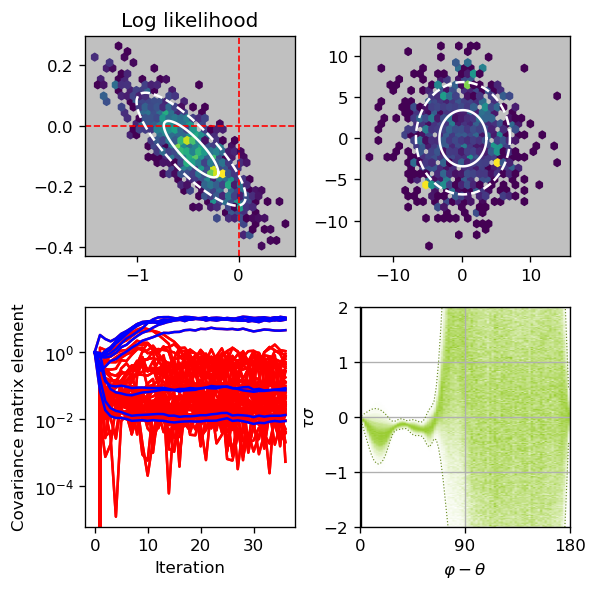

 90%|████████████████████████▎  | 36/40 [4:54:39<29:23, 440.95s/it]

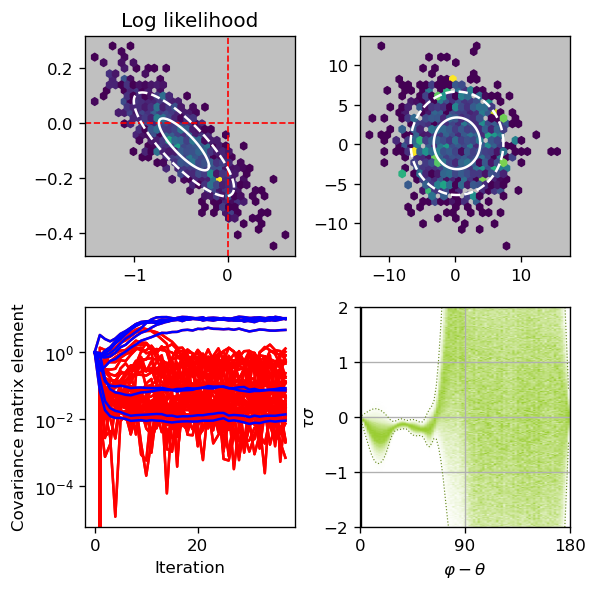

 92%|████████████████████████▉  | 37/40 [5:01:36<21:41, 433.74s/it]

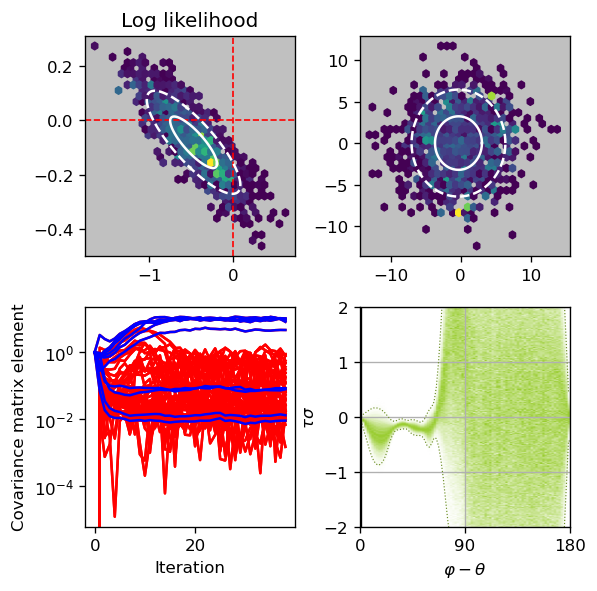

 95%|█████████████████████████▋ | 38/40 [5:08:42<14:22, 431.48s/it]

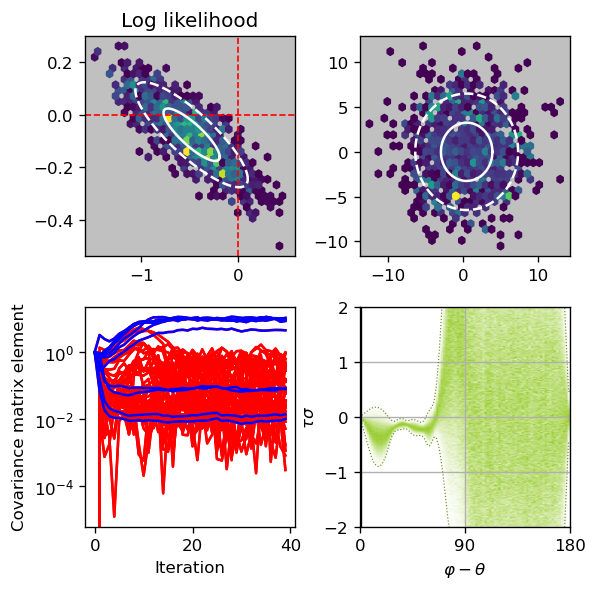

 98%|██████████████████████████▎| 39/40 [5:16:25<07:20, 440.94s/it]

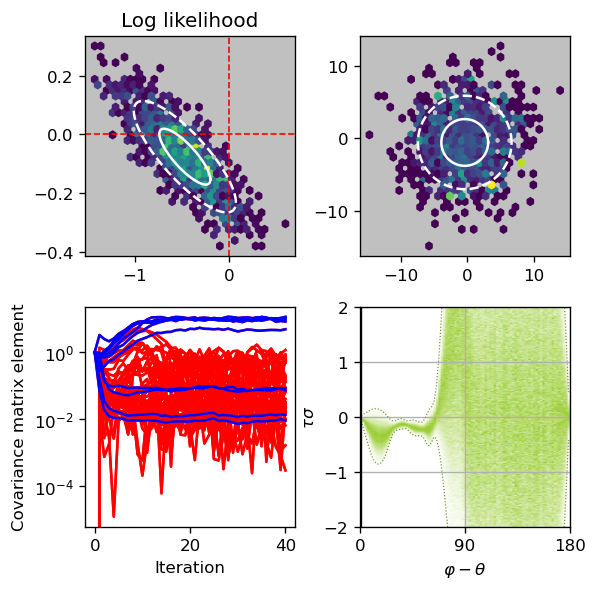

100%|███████████████████████████| 40/40 [5:23:37<00:00, 485.45s/it]


In [10]:
# Set up base run

n_trajectories = 20
x_data = x_data[:n_trajectories, :]
y_data = y_data[:n_trajectories, :]

clipping = np.inf

search_size = 1.5
initial_radius = 1
ndims = 10
centers = np.zeros(ndims)
mean = centers.copy()
cov = np.eye(ndims) * initial_radius**2

COVS = [cov.copy()]
MEANS = [mean.copy()]

count = 0

ALL_COORDS = np.zeros((0, ndims))
ALL_TARGET_DENSITIES = np.zeros(0)
ALL_LIKELIHOODS = np.zeros(0)

COVS = [cov.copy()]
MEANS = [mean.copy()]

learn(x_data,
      y_data,
      progression=range(40),
      sample_count=1024//1,
      particle_count=1500,
      new_samples_only=True,
      torque_scale=2.0,
      clip_parameters=10,
      search_size=search_size,
      mixing_ratio=0.89,
      #smoothing_factor=1., # only 1 is correct
      max_angle = 1000 * np.pi / 180,
      use_Bsplines = True,
      )

mean_1 = mean.copy()
cov_1 = cov.copy()

np.save("mean_1.npy", mean_1)
np.save("cov_1.npy", cov_1)

avg_range = 20
mean_1_avg = np.mean(MEANS[avg_range:], axis=0)
cov_1_avg  = np.mean(COVS[avg_range:], axis=0)
np.save("mean_1_avg.npy", mean_1_avg)
np.save("cov_1_avg.npy", cov_1_avg)

In [ ]:
mean_1r = mean.copy()
cov_1r = cov.copy()

# Spectral Run 1

In [ ]:
# Set up base run

n_trajectories = 20
x_data = x_data[:n_trajectories, :]
y_data = y_data[:n_trajectories, :]

clipping = np.inf

search_size = 1.5
initial_radius = 1
ndims = 4
centers = np.zeros(ndims)
mean = centers.copy()
cov = np.eye(ndims) * initial_radius**2

COVS = [cov.copy()]
MEANS = [mean.copy()]

count = 0

ALL_COORDS = np.zeros((0, ndims))
ALL_TARGET_DENSITIES = np.zeros(0)
ALL_LIKELIHOODS = np.zeros(0)

COVS = [cov.copy()]
MEANS = [mean.copy()]

learn(x_data,
      y_data,
      progression=range(40),
      sample_count=1024//2,
      particle_count=100,
      new_samples_only=True,
      torque_scale=2.0,
      clip_parameters=10,
      search_size=search_size,
      mixing_ratio=0.97,
      smoothing_factor=1.,
      max_angle = 1000 * np.pi / 180,
      use_Bsplines = False,
      )

mean_2 = mean.copy()
cov_2 = cov.copy()

np.save("mean_2.npy", mean_2)
np.save("cov_2.npy", cov_2)

# Spectral 2D

  0%|                                       | 0/10 [00:00<?, ?it/s]

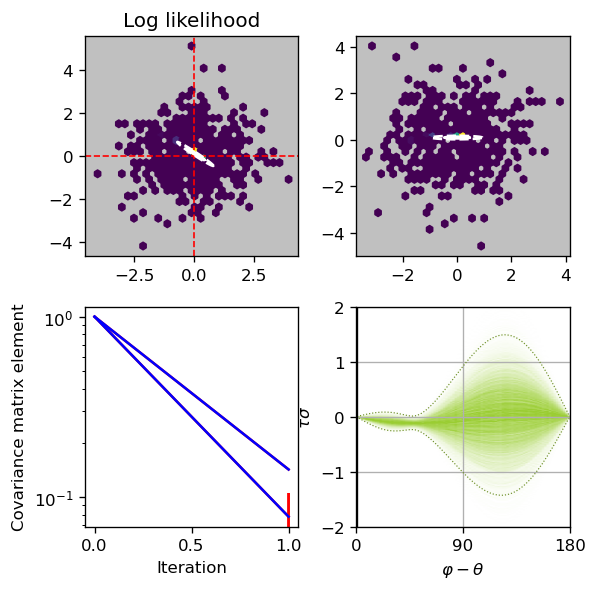

 10%|███                            | 1/10 [00:04<00:37,  4.16s/it]

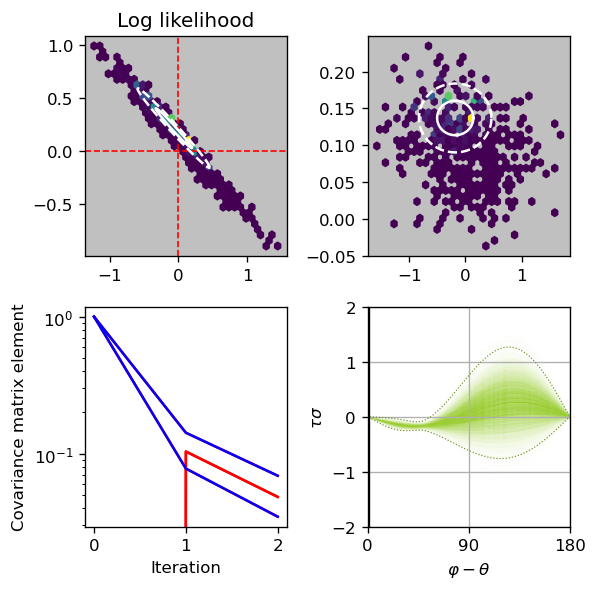

 20%|██████▏                        | 2/10 [00:08<00:33,  4.16s/it]

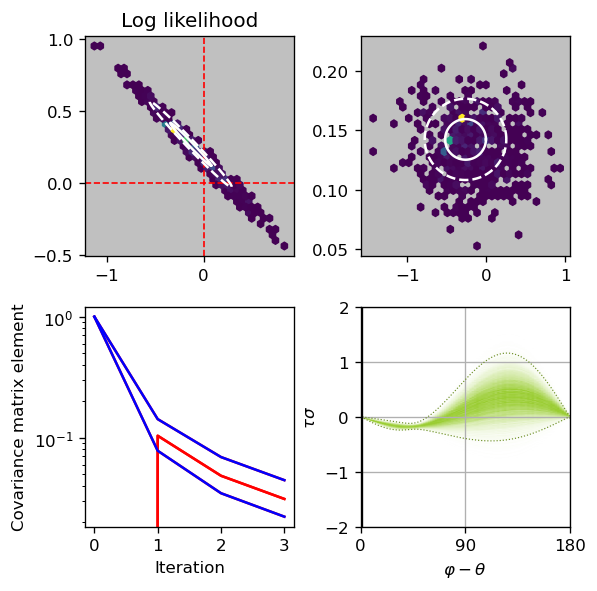

 30%|█████████▎                     | 3/10 [00:12<00:29,  4.28s/it]

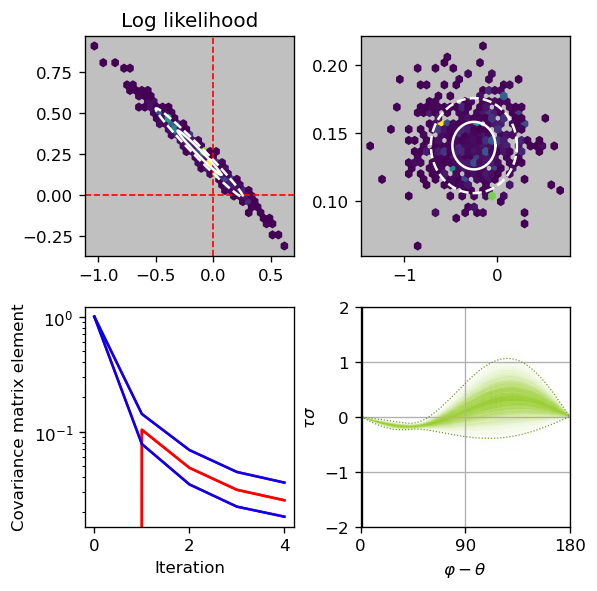

 40%|████████████▍                  | 4/10 [00:17<00:25,  4.28s/it]

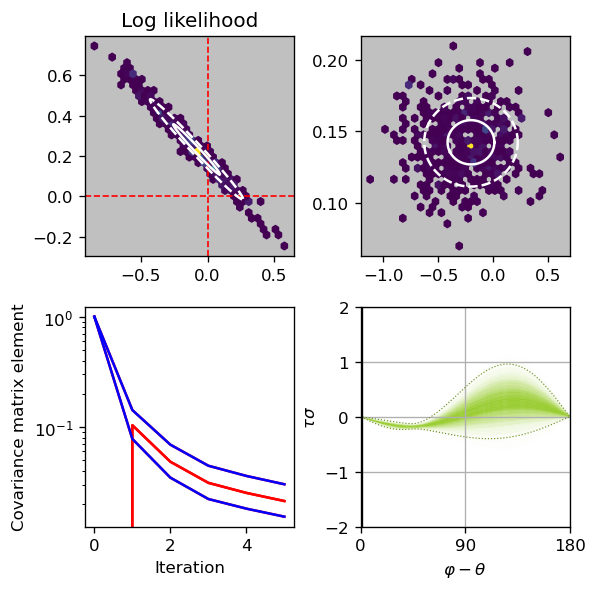

 50%|███████████████▌               | 5/10 [00:21<00:21,  4.28s/it]

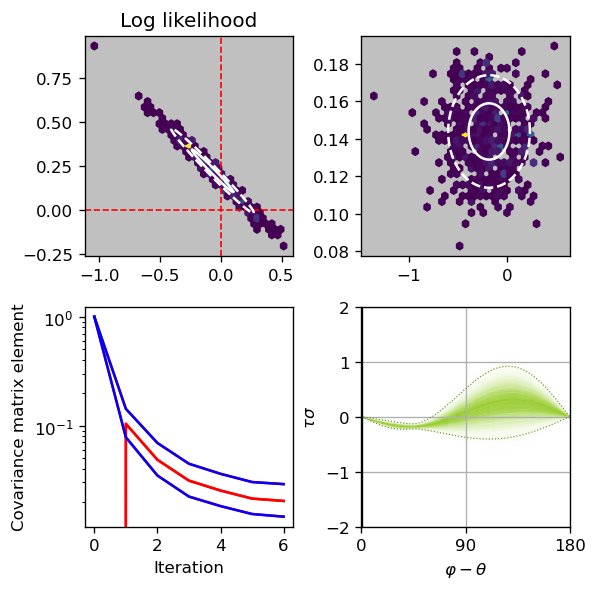

 60%|██████████████████▌            | 6/10 [00:25<00:17,  4.27s/it]

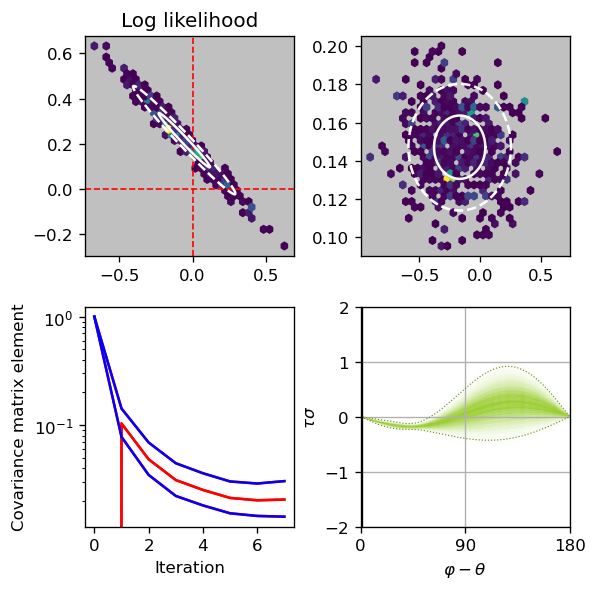

 70%|█████████████████████▋         | 7/10 [00:29<00:12,  4.26s/it]

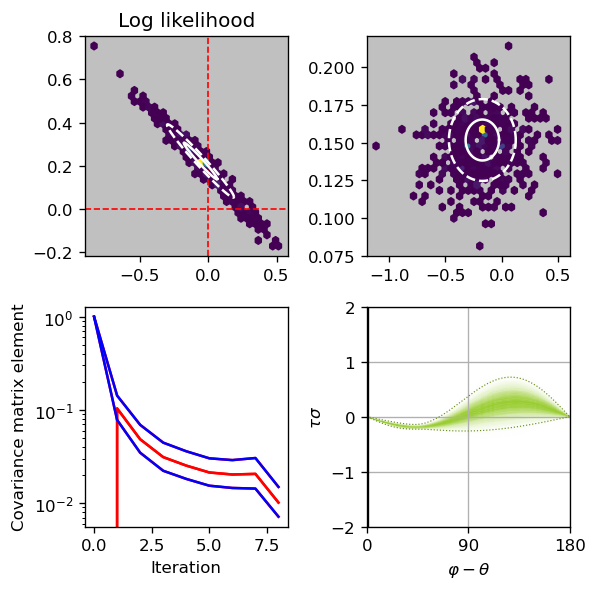

 80%|████████████████████████▊      | 8/10 [00:34<00:08,  4.31s/it]

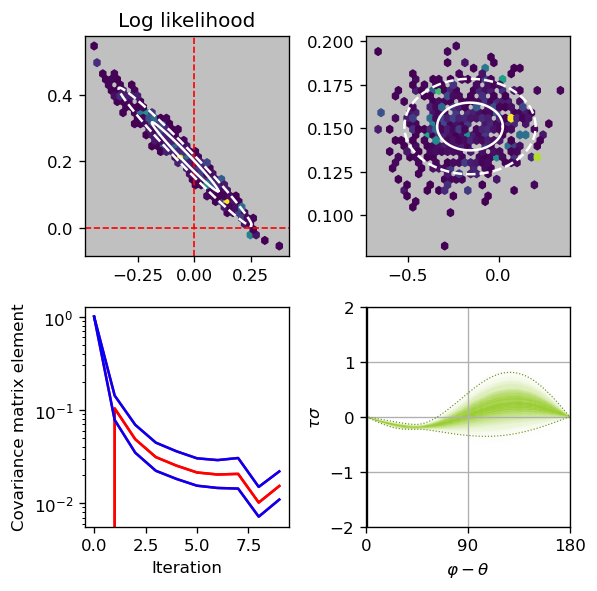

 90%|███████████████████████████▉   | 9/10 [00:38<00:04,  4.30s/it]

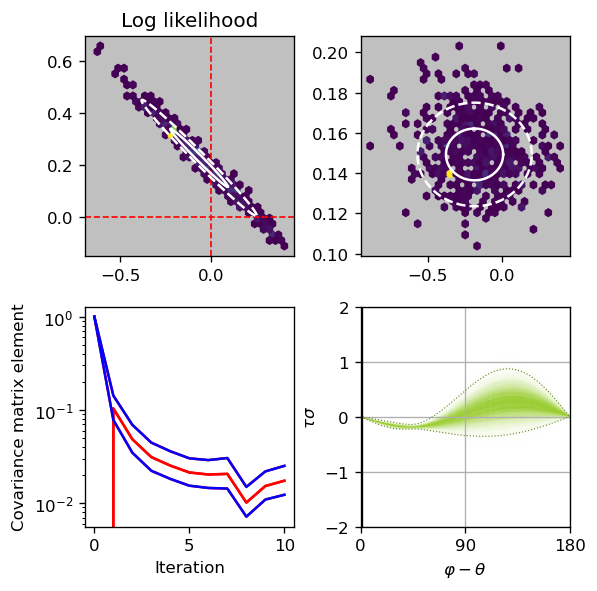

100%|██████████████████████████████| 10/10 [00:42<00:00,  4.29s/it]


In [64]:
# Set up base run

n_trajectories = 20
x_data = x_data[:n_trajectories, :]
y_data = y_data[:n_trajectories, :]

clipping = np.inf

search_size = 1.5
initial_radius = 1
ndims = 2
centers = np.zeros(ndims)
mean = centers.copy()
cov = np.eye(ndims) * initial_radius**2

COVS = [cov.copy()]
MEANS = [mean.copy()]

count = 0

ALL_COORDS = np.zeros((0, ndims))
ALL_TARGET_DENSITIES = np.zeros(0)
ALL_LIKELIHOODS = np.zeros(0)

COVS = [cov.copy()]
MEANS = [mean.copy()]

learn(x_data,
      y_data,
      progression=range(10),
      sample_count=1024//2,
      particle_count=100,
      new_samples_only=True,
      torque_scale=2.0,
      clip_parameters=10,
      search_size=search_size,
      mixing_ratio=0.8,
      smoothing_factor=1.,
      max_angle = 1000 * np.pi / 180,
      use_Bsplines = False,
      )

mean_3 = mean.copy()
cov_3 = cov.copy()

np.save("mean_3.npy", mean_3)
np.save("cov_3.npy", cov_3)

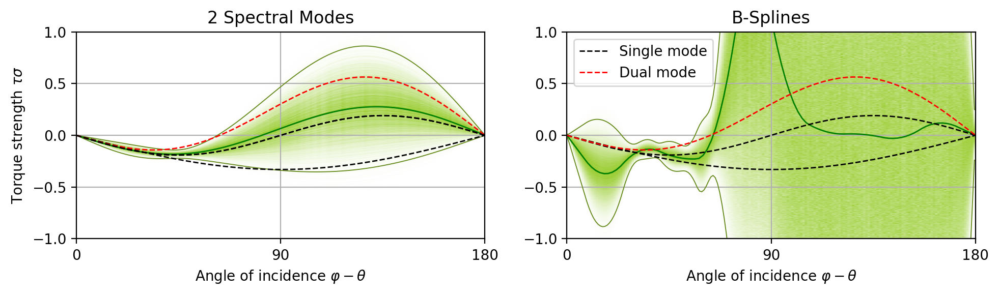

In [8]:
plt.figure(figsize=(10,3), dpi=200)
plt.subplot(1, 2, 1)

mean = np.load("mean_3.npy")
cov  = np.load("cov_3.npy")

phi = np.linspace(0, 180, 100)
plot_torques([mean], [cov], n_samples=10000, n_examples=0, use_Bsplines=False, torque_scale=1, plot_edges=False, n_phis=400)
plt.plot(phi, TORQUE(phi/180*np.pi, mean), c='g', lw=1)
plt.xlim([0,180])
plt.xlabel(r"Angle of incidence $\varphi-\theta$")
plt.ylabel(r"Torque strength $\tau\sigma$")


p = 1.5

# Mode 1
alpha = 0.4725 * p - 0.4146
t = -alpha/Q2 * np.sin(2*np.pi/180 * phi)
plt.plot(phi, t, '--k', lw=1, label="Single mode")

# Mode 2
alpha = 0.833 * p - 0.74
t = -alpha/Q2 * np.sin(1*np.pi/180 * phi)
plt.plot(phi, t, '--k', lw=1)

# Dual Mode
alpha1 = -0.517
alpha2 = 0.467
t = alpha2/Q2 * np.sin(1*np.pi/180 * phi) + alpha1/Q2 * np.sin(2*np.pi/180 * phi)
plt.plot(phi, t, '--r', lw=1, label='Dual mode')


# Mode 2
alpha = 0.4725 * p - 0.4146
t = -alpha/Q2 * np.sin(2*np.pi/180 * phi)
plt.plot(phi, t, '--k', lw=1, label="Single mode")

plt.title("2 Spectral Modes")

#plt.legend()


# ----------------------------------------------------------------------------

plt.subplot(1, 2, 2)

mean = np.load("mean_1_avg.npy")
cov  = np.load("cov_1_avg.npy")

#mean = np.load("mean_2.npy")
#cov  = np.load("cov_2.npy")


plot_torques([mean], [cov], n_samples=100000, n_examples=0, use_Bsplines=True, torque_scale=1, plot_edges=False, n_phis=400)
plt.plot(phi, TORQUE_BSPLINE(phi/180*np.pi, mean), c='g', lw=1)
plt.xlim([0,180])
plt.xlabel(r"Angle of incidence $\varphi-\theta$")
#plt.ylabel(r"Torque strength $\tau\sigma$")

phi = np.linspace(0, 180, 100)
p = 1.5

# Mode 1
alpha = 0.4725 * p - 0.4146
t = -alpha/Q2 * np.sin(2*np.pi/180 * phi)
plt.plot(phi, t, '--k', lw=1, label="Single mode")

# Mode 2
alpha = 0.833 * p - 0.74
t = -alpha/Q2 * np.sin(1*np.pi/180 * phi)
plt.plot(phi, t, '--k', lw=1)

# Dual Mode
alpha1 = -0.517
alpha2 = 0.467
t = alpha2/Q2 * np.sin(1*np.pi/180 * phi) + alpha1/Q2 * np.sin(2*np.pi/180 * phi)
plt.plot(phi, t, '--r', lw=1, label='Dual mode')

plt.legend()
plt.tight_layout()
plt.title("B-Splines")
plt.savefig("comparison_results.png", dpi=400)
plt.show()

# MCMC (Spectral)

In [ ]:
n_chains = 20
n_dims = 4

n_trajectories = 20
x_data = x_data[:n_trajectories, :]
y_data = y_data[:n_trajectories, :]

mean_2 = np.load("mean_2.npy")
cov_2 = np.load("cov_2.npy")
mean = mean_2
cov = cov_2

n_particles = 1000

proposal_distro = multivariate_normal(mean=mean, cov=cov)
state = proposal_distro.rvs(size=n_chains)
state_likelihood = proposal_distro.logpdf(state)

logl, _, _ = calc_logl_core(x_data, y_data, dt,
                                PE, DT, DR, FORCE_STRENGTH,
                                state, torque_limit=np.inf,
                                n_particles=n_particles,
                                clip_params=10,
                                use_Bsplines=False,
                                )

STATES = [state.copy()]
for i in tqdm(range(150)):
    proposal = proposal_distro.rvs(size=n_chains)
    proposal_likelihood = proposal_distro.logpdf(proposal)
    new_logl, _, _ = calc_logl_core(x_data, y_data, dt,
                                        PE, DT, DR, FORCE_STRENGTH,
                                        state, torque_limit=np.inf,
                                        n_particles=n_particles,
                                        clip_params=10,
                                        use_Bsplines=False,
                                        )
    delta_logl = new_logl - logl# + state_likelihood - proposal_likelihood
    threshold = np.log(np.random.rand(n_chains))
    rejects = threshold > delta_logl

    new_logl[rejects] = logl[rejects]
    proposal[rejects] = state[rejects]
    
    logl = new_logl
    state = proposal
    STATES.append(state.copy())

chains = np.stack(STATES)
plt.plot(chains[:,:,0], alpha=0.5, lw=1)
plt.show()

In [ ]:
n_samples, n_chains, n_dims = chains.shape


for c in range(n_chains):
    plt.hist(chains[:, c, 0], alpha=0.1)
    plt.show()

In [ ]:
chains = np.stack(STATES)
plt.plot(chains[:,:,0], lw=1, ls='--', alpha=0.5, )